# Setup

## Imports

In [1]:
%load_ext autoreload
%autoreload 2

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from src.constants import DATASETS_DIR
from src.data_loading import load_csv_data, parse_preprocessing_config
from src.dataset_config import load_dataset_config
from src.preprocessing import filter_doublets, normalize_by_library_size, log_transform, normalize_with_pearson
from src.preprocessing.gene_annotation import load_gene_annotation
from src.preprocessing.gene_sets import duplicated_genes, matching_genes, rrna_genes, unmatched_genes
from src.preprocessing.pipeline import run_filtering_pipeline
from src.preprocessing.qc_metrics import cell_qc_metrics
from src.visualization import (
    plot_qc_overview,
    plot_gene_set_qc,
    plot_gene_max_count_distribution,
    plot_normalization_comparison,
    plot_log_transform_comparison,
)

## Data Loading

In [3]:
from src.data_loading import load_csv_data

DATA_PATH = DATASETS_DIR / 'GSE118767_10x_5cl' / 'interim' / 'counts.csv.gz'
raw_data = load_csv_data(DATA_PATH)

raw_data

,ENSG00000196970,ENSG00000123500,ENSG00000240631,ENSG00000230251,ENSG00000146453,ENSG00000226617,ENSG00000240449,ENSG00000227544,ENSG00000233595,ENSG00000228078,...,ENSG00000146755,ENSG00000135480,ENSG00000277449,ENSG00000162739,ENSG00000128340,ENSG00000154122,ENSG00000253805,ENSG00000276945,ENSG00000265010,ENSG00000249456
cell_id,,,,,,,,,,,,,,,,,,,,,
Lib90_00000,0,0,0,0,0,0,0,0,0,0,...,0,296,0,0,3,0,0,0,0,0
Lib90_00002,0,0,0,0,0,0,0,0,0,0,...,0,38,0,0,0,0,0,0,0,0
Lib90_00003,0,0,0,0,0,0,0,0,0,0,...,0,155,0,0,9,0,0,0,0,0
Lib90_00004,0,0,0,0,0,0,0,0,0,0,...,0,442,0,0,5,0,0,0,0,0
Lib90_00005,0,0,0,0,0,0,0,0,0,0,...,0,150,0,0,8,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Lib90_04026,0,0,0,0,0,0,0,0,0,0,...,0,22,0,0,0,0,0,0,0,0
Lib90_04028,0,0,0,0,0,0,0,0,0,0,...,0,13,0,0,0,0,0,0,0,0
Lib90_04029,0,0,0,0,0,0,0,0,0,0,...,0,3,0,0,0,0,0,0,0,0


## Dataset config

In [4]:
DATASET_DIR = DATASETS_DIR / 'GSE118767_10x_5cl'

dataset_config = load_dataset_config(DATASET_DIR / 'config.yaml')
SPECIES = dataset_config["species"]
preprocessing_config = parse_preprocessing_config(dataset_config)

preprocessing_config

PreprocessingConfig(mito_threshold=0.2, min_gene_max_count=2, count_threshold=None, gene_threshold=None)

# Quality Control

In [5]:
qc_metrics = cell_qc_metrics(raw_data, species=SPECIES)

print(qc_metrics.median().round(3))
display(qc_metrics.head(5).round(3))
display(qc_metrics.tail(5).round(3))

count_depth           25327.000
n_genes                4700.000
mito_fraction             0.062
rrna_fraction             0.010
apoptosis_fraction        0.012
dtype: float64


,count_depth,n_genes,mito_fraction,rrna_fraction,apoptosis_fraction
cell_id,,,,,
Lib90_00000,104055,8344,0.069,0.012,0.012
Lib90_00002,93744,8121,0.051,0.007,0.011
Lib90_00003,89426,7809,0.060,0.010,0.011
Lib90_00004,87517,7807,0.043,0.005,0.011
Lib90_00006,82620,7549,0.045,0.004,0.024


,count_depth,n_genes,mito_fraction,rrna_fraction,apoptosis_fraction
cell_id,,,,,
Lib90_03989,5340,2027,0.090,0.022,0.011
Lib90_04017,5339,1780,0.108,0.018,0.007
Lib90_03991,5333,1664,0.069,0.012,0.016
Lib90_03941,5200,1724,0.071,0.017,0.011
Lib90_04029,5162,1712,0.080,0.011,0.007


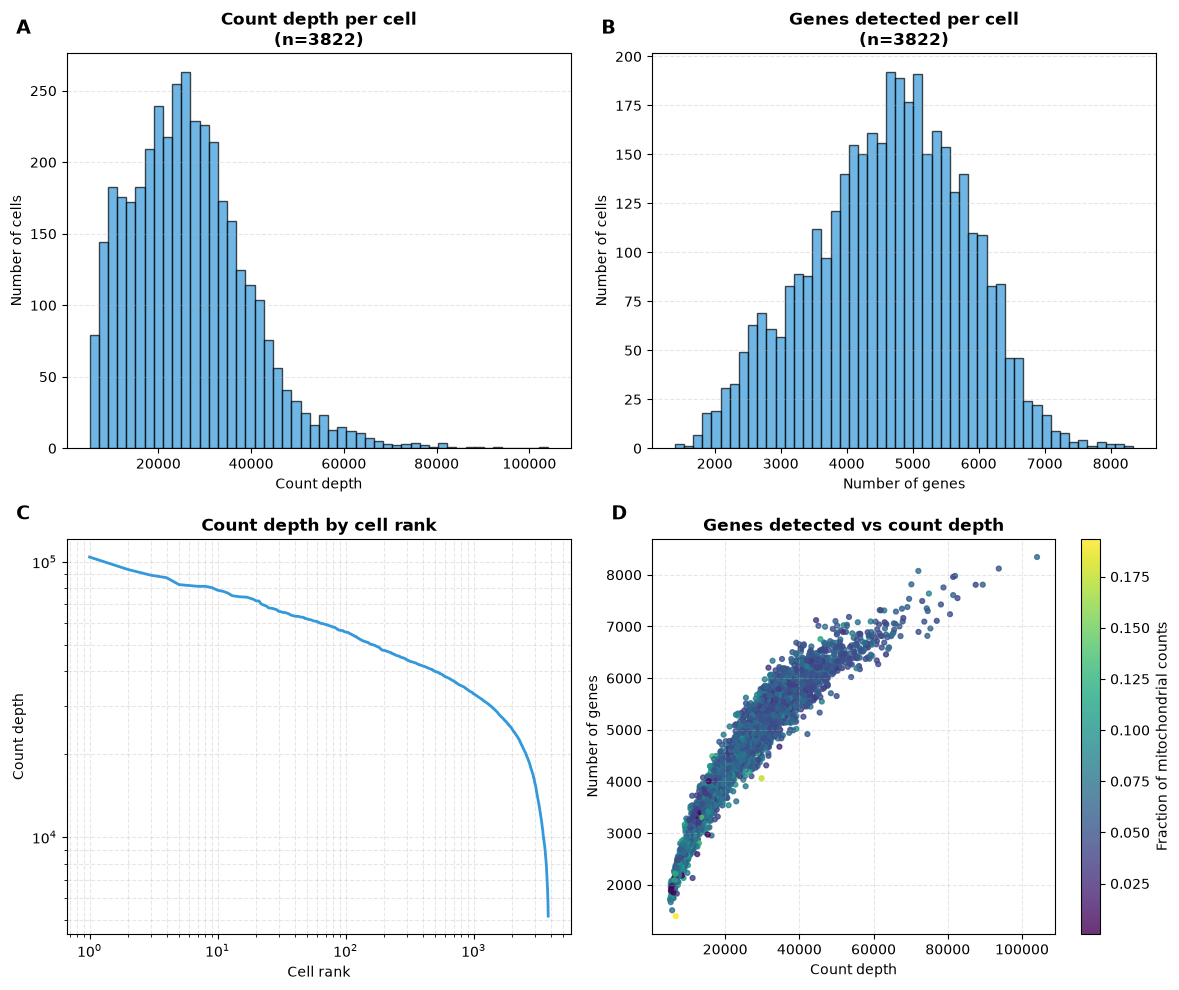

In [6]:
plot_qc_overview(
    raw_data,
    species=SPECIES,
    count_threshold=preprocessing_config.count_threshold,  # minimum count depth, set in the dataset config
    gene_threshold=preprocessing_config.gene_threshold,    # minimum genes per cell, set in the dataset config
)

## Mitochondrial, rRNA and apoptosis fractions

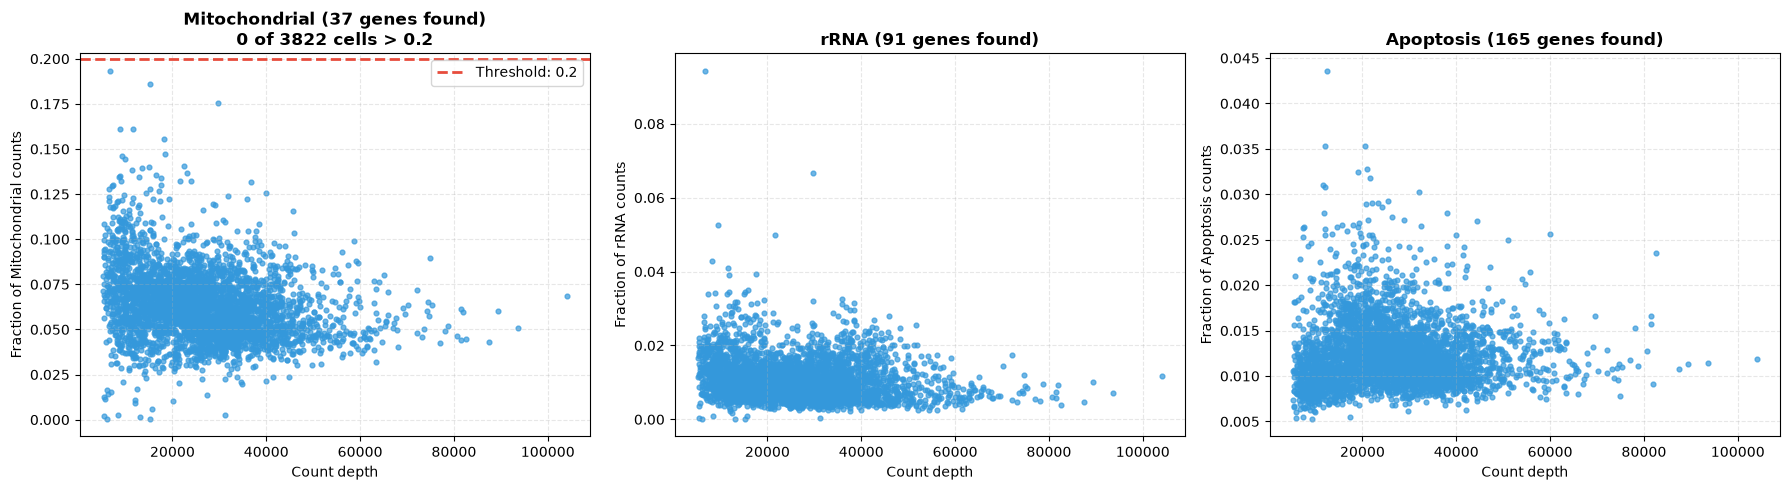

In [7]:
plot_gene_set_qc(raw_data, SPECIES, preprocessing_config)

## Genes

### Uniqueness

In [8]:
duplicates = duplicated_genes(raw_data)

print(f"Gene columns: {raw_data.shape[1]}, unique gene names: {raw_data.columns.nunique()}")
print(f"Gene names appearing in more than one column: {len(duplicates)}")
display(duplicates)

assert duplicates.empty, "Duplicated gene names found, see the table above"

Gene columns: 32895, unique gene names: 32895
Gene names appearing in more than one column: 0


,n_columns,identical_counts
gene,,


### Missing from the annotation

In [9]:
annotation = load_gene_annotation(SPECIES)
unmatched = unmatched_genes(raw_data, annotation)
alias_hits = unmatched.alias_matches
n_alias_genes = alias_hits["gene"].nunique()
n_ambiguous = alias_hits.loc[alias_hits["n_matches"] > 1, "gene"].nunique()

print(f"Genes matching no gene_id or gene_name: {n_alias_genes + len(unmatched.unknown_ensembl_ids) + len(unmatched.other)} / {raw_data.shape[1]}")
print(f"  found through alias_names: {n_alias_genes} ({n_ambiguous} matching more than one annotation row)")
print(f"  Ensembl IDs missing from the annotation: {len(unmatched.unknown_ensembl_ids)}, e.g. {unmatched.unknown_ensembl_ids[:5]}")
print(f"  other: {len(unmatched.other)}, e.g. {unmatched.other[:5]}")
display(alias_hits)

Genes matching no gene_id or gene_name: 770 / 32895
  found through alias_names: 0 (0 matching more than one annotation row)
  Ensembl IDs missing from the annotation: 770, e.g. ['ENSG00000227895', 'ENSG00000264421', 'ENSG00000263081', 'ENSG00000198106', 'ENSG00000281112']
  other: 0, e.g. []


,gene,n_matches,gene_id,gene_name,gene_biotype,chromosome,MT_status,RB_status,TF_status,APOPT_status,alias_names


### rRNA

In [10]:
# Same matching as filter_rrna_genes, so these are exactly the columns the pipeline drops
rrna_columns = matching_genes(raw_data, rrna_genes(SPECIES, annotation))
rrna_counts = raw_data[rrna_columns].sum().sort_values(ascending=False).rename("total_counts")

print(f"rRNA genes filtered out: {len(rrna_columns)} / {raw_data.shape[1]}")
print(f"  share of all counts: {rrna_counts.sum() / raw_data.values.sum():.3f}")
display(rrna_counts.to_frame())

rRNA genes filtered out: 91 / 32895
  share of all counts: 0.010


,total_counts
ENSG00000210082,820584
ENSG00000211459,225651
ENSG00000275215,242
ENSG00000202502,116
ENSG00000200370,55
...,...
ENSG00000222838,1
ENSG00000251823,1
ENSG00000212576,1
ENSG00000200275,1


## Filtering pipeline

In [11]:
clean_data = run_filtering_pipeline(raw_data, config=preprocessing_config, species=SPECIES)

clean_data.shape

(3822, 18516)

### Low expression genes

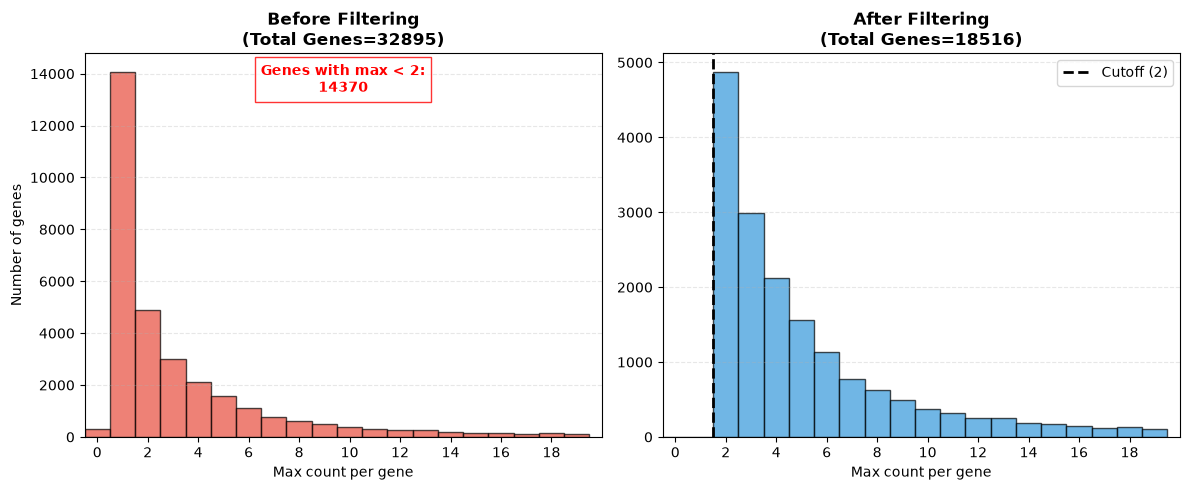

In [12]:
plot_gene_max_count_distribution(raw_data, clean_data, x_limit=20)

## Doublets (demonstration only)

We run the doublet filter to show how many cells it would remove, but the rest of the notebook continues from `clean_data`.

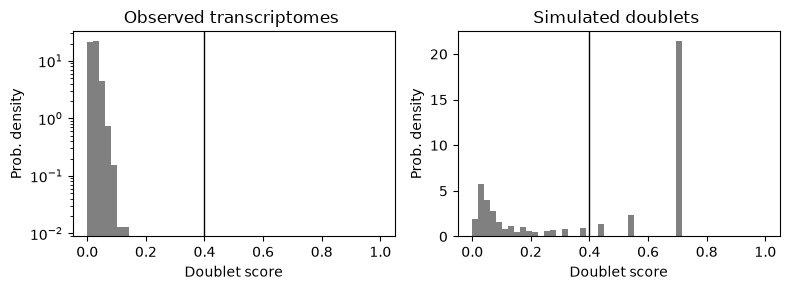

Cells removed as doublets: 0 / 3822


In [13]:
# For demonstration only: the rest of the notebook continues from clean_data, not from no_doublets_data
no_doublets_data = filter_doublets(clean_data)

print(f"Cells removed as doublets: {clean_data.shape[0] - no_doublets_data.shape[0]} / {clean_data.shape[0]}")

# Normalization

## logCPM

### Normalize by library size

In [14]:
normalized_data = normalize_by_library_size(clean_data)

normalized_data.shape

(3822, 18516)

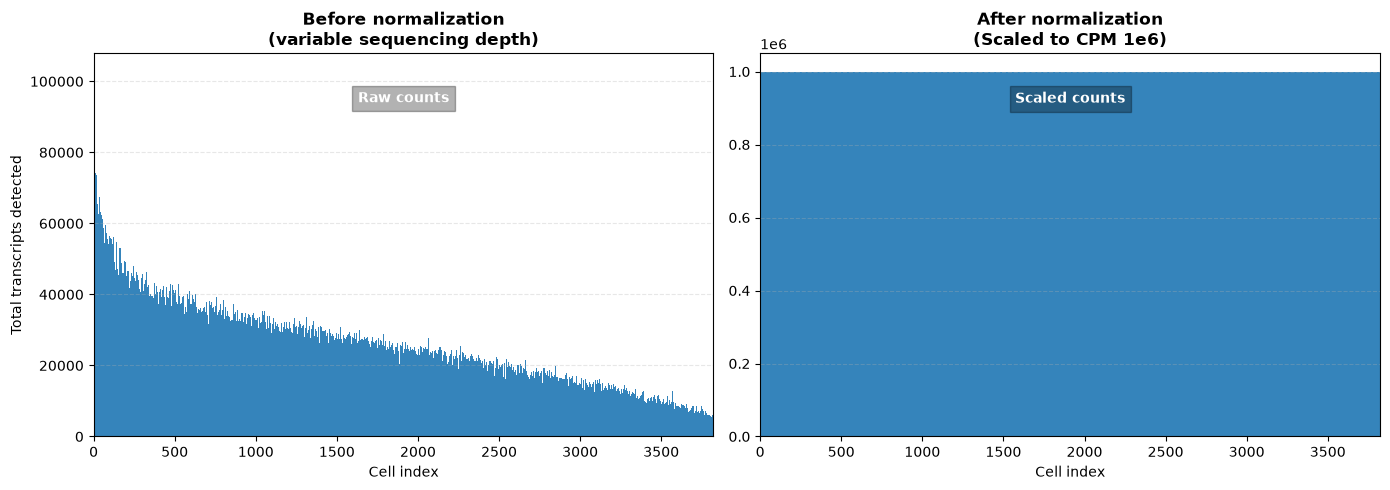

In [15]:
plot_normalization_comparison(clean_data, normalized_data, n_cells=normalized_data.shape[0])

### Log Transform

In [16]:
logged_data = log_transform(normalized_data)

logged_data.shape

(3822, 18516)

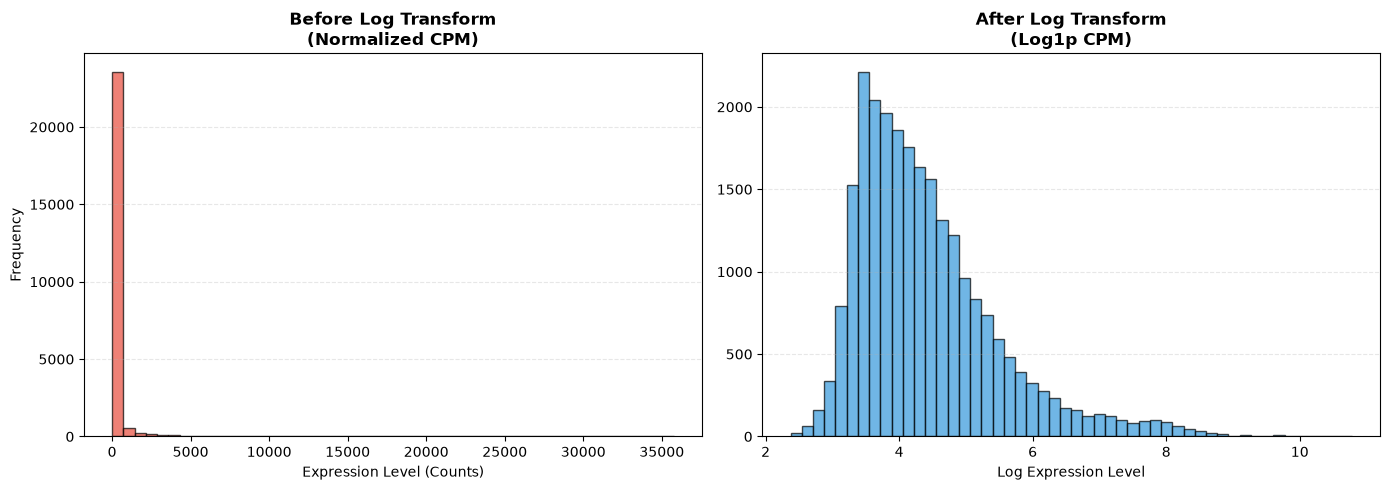

In [17]:
plot_log_transform_comparison(normalized_data, logged_data)

## Pearson residuals

In [18]:
pearsons_data = normalize_with_pearson(clean_data)

pearsons_data.shape

(3822, 18516)

In [19]:
pearsons_data.head()

,ENSG00000247699,ENSG00000234859,ENSG00000206072,ENSG00000136696,ENSG00000237250,ENSG00000253311,ENSG00000130294,ENSG00000238280,ENSG00000232537,ENSG00000225891,...,ENSG00000148218,ENSG00000084623,ENSG00000205531,ENSG00000144827,ENSG00000134874,ENSG00000240235,ENSG00000170113,ENSG00000135480,ENSG00000128340,ENSG00000154122
cell_id,,,,,,,,,,,,,,,,,,,,,
Lib90_00000,-0.045378,-0.045378,-0.064173,-0.055576,-0.055576,-0.064173,-0.120051,-0.045378,-0.045378,-0.055576,...,-1.058713,-1.921435,-1.381802,2.051489,-0.673823,-0.055576,-0.916642,7.318197,0.584630,-0.913877
Lib90_00002,-0.043169,-0.043169,-0.061050,-0.052871,-0.052871,-0.061050,-0.114209,-0.043169,-0.043169,-0.052871,...,-0.025471,3.440067,-1.206084,0.129892,0.912069,-0.052871,-0.872381,-5.517025,-1.377260,-0.869747
Lib90_00003,-0.042103,-0.042103,-0.059542,-0.051565,-0.051565,-0.059542,-0.111389,-0.042103,-0.042103,-0.051565,...,1.031686,-2.120865,-1.928864,-0.909962,-0.625395,-0.051565,-0.850991,1.364389,5.232302,-0.848421
Lib90_00004,-0.041764,-0.041764,-0.059062,-0.051149,-0.051149,-0.059062,-0.110490,-0.041764,-0.041764,-0.051149,...,-0.975225,-0.129067,-1.498995,2.393663,-0.620370,-0.051149,1.508112,18.189998,2.350447,-0.841627
Lib90_00005,-0.040315,-0.040315,-0.057013,-0.049375,-0.049375,-0.057013,-0.106658,-0.040315,-0.040315,-0.049375,...,-0.941702,-1.070348,-1.391835,-0.871613,-0.598930,-0.049375,1.622316,1.822808,4.821604,0.409819
